In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Generating a (starting) BA network

In [5]:
def generate_ba_graph(N, m=3, seed=42):
    """
    Generates a Barabási-Albert (BA) graph starting from a four-node clique.

    Parameters:
        N (int): Total number of nodes in the final network.
        m (int): Number of edges to attach from a new node to existing nodes.
        seed (int): Seed for reproducibility.

    Returns:
        G (networkx.Graph): Generated BA graph.
    """
    # Start with a 4-node fully connected graph (clique)
    initial_graph = nx.complete_graph(4)
    
    # Generate the BA graph
    G = nx.barabasi_albert_graph(N, m, seed=seed, initial_graph=initial_graph)
    return G

In [6]:
G_start = generate_ba_graph(1000)

In [7]:
G = G_start

In [8]:
G = nx.read_graphml("test_networks/ba_graph_1000.graphml")

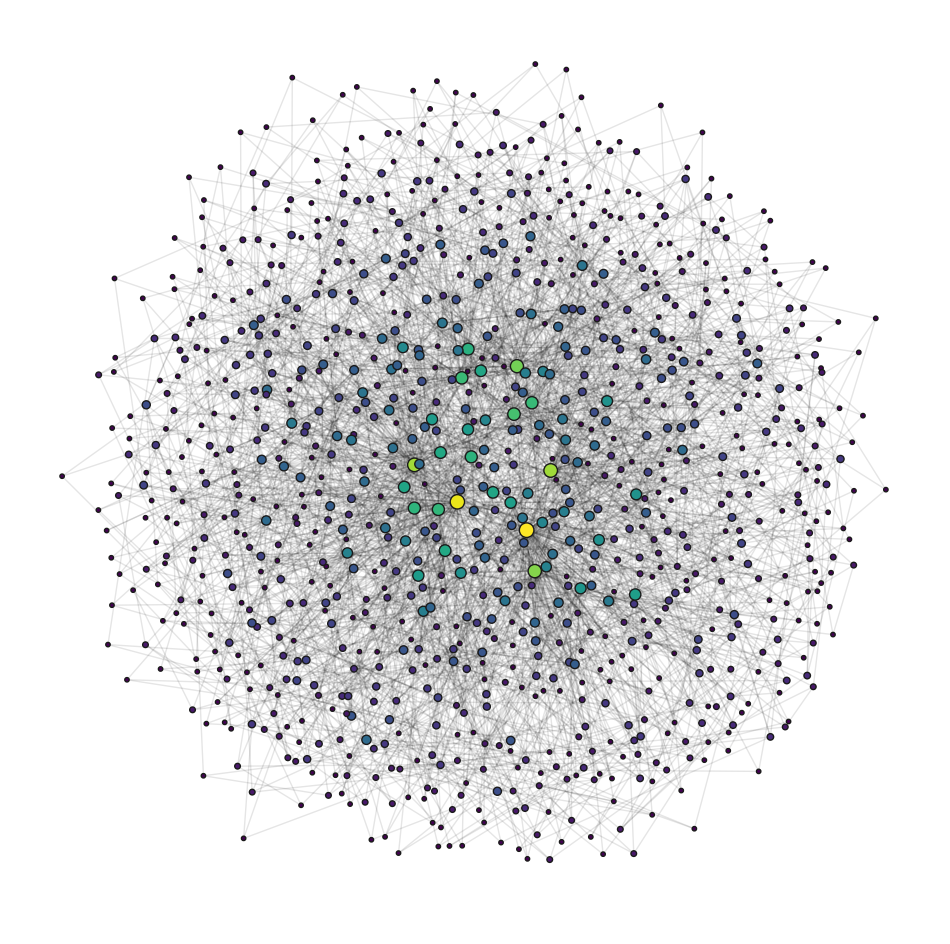

In [9]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm

# Keep only the largest connected component
largest_cc = max(nx.connected_components(G), key=len)
G_largest = G.subgraph(largest_cc).copy()

# Sort nodes by degree (ascending), so high-degree nodes are processed last
sorted_nodes = sorted(G_largest.nodes(), key=lambda x: G_largest.degree[x], reverse=True)

# Relabel the graph nodes to ensure sorted order is reflected
mapping = {node: i for i, node in enumerate(sorted_nodes)}
G_largest = nx.relabel_nodes(G_largest, mapping)

# Recalculate node degrees (now sorted)
degree = dict(G_largest.degree())
nx.set_node_attributes(G_largest, degree, 'degree')

# Node size based on degree (logarithmic scaling)
degrees = np.array(list(degree.values()))
degrees += 1  # Avoid log(0) by shifting values
node_sizes = 10 + 100 * (np.log(degrees) - np.log(degrees.min())) / (
    np.log(degrees.max()) - np.log(degrees.min())
)

# Node color based on degree (logarithmic scaling)
cmap = plt.cm.viridis
node_colors = cmap((np.log(degrees) - np.log(degrees.min())) / (np.log(degrees.max()) - np.log(degrees.min())))

# Calculate edge betweenness centrality (for edge width and alpha)
edge_betweenness = nx.edge_betweenness_centrality(G_largest)
edge_widths = [1 + 7 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale edge widths for visibility
edge_alphas = [0.1 + 0.6 * edge_betweenness[edge] for edge in G_largest.edges()]  # Scale alpha from 0.1 to 1.0

# Positioning nodes using a force-directed layout
pos = nx.kamada_kawai_layout(G_largest)

# Plot the network
plt.figure(figsize=(12, 12))
# Draw edges with scaled widths and alphas
for edge, width, alpha in zip(G_largest.edges(), edge_widths, edge_alphas):
    nx.draw_networkx_edges(
        G_largest,
        pos,
        edgelist=[edge],
        width=width,
        alpha=alpha,
        edge_color="black",
    )

# Draw nodes with size and color mapped to attributes
nx.draw_networkx_nodes(
    G_largest,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=cmap,
    edgecolors='k',  # Add a border to nodes for clarity
)

# Remove labels and title for a cleaner plot
plt.gca().set_facecolor("black")

# Hide axes for cleaner visualization
plt.axis('off')
plt.savefig('./figures/ba_graph_1000_layout.pdf', dpi = 1000, bbox_inches='tight')
plt.show()

In [13]:
nx.write_graphml(G, "test_networks/ba_graph_1000.graphml")

In [11]:
2 * G.number_of_edges() / G.number_of_nodes()

5.988

# Init Fitter

In [6]:
G = nx.read_graphml("test_networks/ba_graph_1000.graphml")

In [6]:
# 2 * G.number_of_edges() / G.number_of_nodes()

In [7]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+1)

2  k_max:  10
3  k_max:  7
5  k_max:  5
6  k_max:  4
7  k_max:  4


In [ ]:
#import pickle
#with open('./test_networks/ba_graph_1000_mfnf.pkl', 'rb') as f:
#    mfnf = pickle.load(f)

In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 200,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.102578
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:04.123882


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 2994},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 44481},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 305},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 799770},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 11},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 446141},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 35622},
 {'name': 'fou

# Grid Search

In [10]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,10]},
                {'m': 3,  'k': [1,7]},
                {'m': 5,  'k': [1,5]},
                {'m': 6,  'k': [1,4]},
                {'m': 7,  'k': [1,4]}],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_divergence'
)

[I 2025-02-19 07:58:51,355] A new study created in memory with name: no-name-f5488525-afba-443e-9c19-9bc79c248650


Grid Search requires 9 trials...


[I 2025-02-19 07:59:09,246] Trial 0 finished with value: 0.24354898819665008 and parameters: {'m': 2, 'k': 8}. Best is trial 0 with value: 0.24354898819665008.
[I 2025-02-19 07:59:22,553] Trial 1 finished with value: 0.18472174174456818 and parameters: {'m': 2, 'k': 3}. Best is trial 1 with value: 0.18472174174456818.
[I 2025-02-19 07:59:35,205] Trial 2 finished with value: 0.19951925899289868 and parameters: {'m': 2, 'k': 2}. Best is trial 1 with value: 0.18472174174456818.
[I 2025-02-19 07:59:45,845] Trial 3 finished with value: 0.18840604247507203 and parameters: {'m': 2, 'k': 5}. Best is trial 1 with value: 0.18472174174456818.
[I 2025-02-19 08:00:16,407] Trial 4 finished with value: 0.2564540375665491 and parameters: {'m': 2, 'k': 9}. Best is trial 1 with value: 0.18472174174456818.
[I 2025-02-19 08:00:29,679] Trial 5 finished with value: 0.23158941472690106 and parameters: {'m': 2, 'k': 7}. Best is trial 1 with value: 0.18472174174456818.
[I 2025-02-19 08:00:42,463] Trial 6 finis

Grid Search requires 6 trials...


[I 2025-02-19 08:02:46,301] Trial 0 finished with value: 0.23150766137800144 and parameters: {'m': 3, 'k': 6}. Best is trial 0 with value: 0.23150766137800144.
[I 2025-02-19 08:03:17,095] Trial 1 finished with value: 0.1939736454541448 and parameters: {'m': 3, 'k': 3}. Best is trial 1 with value: 0.1939736454541448.
[I 2025-02-19 08:03:55,798] Trial 2 finished with value: 0.2583861978365683 and parameters: {'m': 3, 'k': 2}. Best is trial 1 with value: 0.1939736454541448.
[I 2025-02-19 08:04:30,559] Trial 3 finished with value: 0.19013168168980432 and parameters: {'m': 3, 'k': 4}. Best is trial 3 with value: 0.19013168168980432.
[I 2025-02-19 08:04:59,324] Trial 4 finished with value: 0.43266846604671716 and parameters: {'m': 3, 'k': 1}. Best is trial 3 with value: 0.19013168168980432.
[I 2025-02-19 08:05:37,568] Trial 5 finished with value: 0.215221370406526 and parameters: {'m': 3, 'k': 5}. Best is trial 3 with value: 0.19013168168980432.
[I 2025-02-19 08:05:37,569] A new study create

Grid Search requires 4 trials...


... (2 outputs left out)

[I 2025-02-19 08:16:00,086] Trial 0 finished with value: 0.14988347726544438 and parameters: {'m': 6, 'k': 3}. Best is trial 0 with value: 0.14988347726544438.
[I 2025-02-19 08:18:08,205] Trial 1 finished with value: 0.11831933637465615 and parameters: {'m': 6, 'k': 2}. Best is trial 1 with value: 0.11831933637465615.
[I 2025-02-19 08:19:03,023] Trial 2 finished with value: 0.30658423862280965 and parameters: {'m': 6, 'k': 1}. Best is trial 1 with value: 0.11831933637465615.
[I 2025-02-19 08:19:03,025] A new study created in memory with name: no-name-ab2c1bab-0b82-404c-9ee7-6f6090e6380d


Grid Search requires 3 trials...


[I 2025-02-19 08:23:23,720] Trial 0 finished with value: 0.1281321416015346 and parameters: {'m': 7, 'k': 3}. Best is trial 0 with value: 0.1281321416015346.
[I 2025-02-19 08:25:55,134] Trial 1 finished with value: 0.1655934264359485 and parameters: {'m': 7, 'k': 2}. Best is trial 0 with value: 0.1281321416015346.
[I 2025-02-19 08:27:22,260] Trial 2 finished with value: 0.2810462761472334 and parameters: {'m': 7, 'k': 1}. Best is trial 0 with value: 0.1281321416015346.


Best parameters:  {'m': 6, 'k': 2}
Best energy:  7.637351150543929
Best KL-divergence:  0.11831933637465615
Best KLD augumented energy: 3.1380202023210817
Best P matrix:
 [[0.03256537 0.08769749 0.15525035 0.27212262 0.19023292 0.32080686]
 [0.08769749 0.06780731 0.18210335 0.43119452 0.1666537  0.60312099]
 [0.15525035 0.18210335 0.1668983  0.63294678 0.51232006 0.84798102]
 [0.27212262 0.43119452 0.63294678 0.90663784 0.80683061 0.91585601]
 [0.19023292 0.1666537  0.51232006 0.80683061 0.21517583 0.65107079]
 [0.32080686 0.60312099 0.84798102 0.91585601 0.65107079 0.98501343]]
Best l vector:
 [0.81354116 0.08707831 0.06273279 0.02614667 0.00700155 0.00487098]


In [11]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 2994,
  'expected_count': 2902,
  'MRE': 0.03072812291249165},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 44481,
  'expected_count': 43098,
  'MRE': 0.031091926890132866},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 305,
  'expected_count': 337,
  'MRE': 0.09495548961424333},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 799770,
  'expected_count': 615313,
  'MRE': 0.23063755829801066},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 11,
  'expected_count': 11,
  'MRE': 0.0},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1

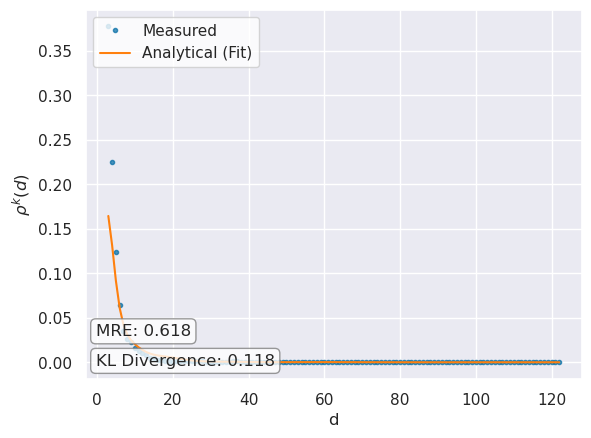

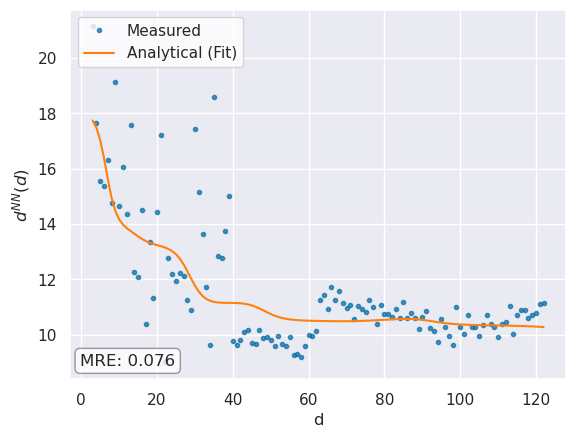

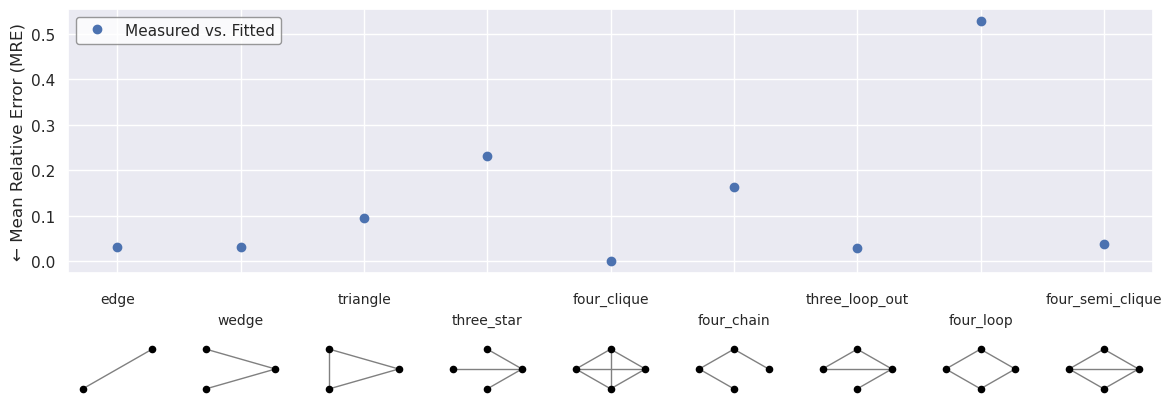

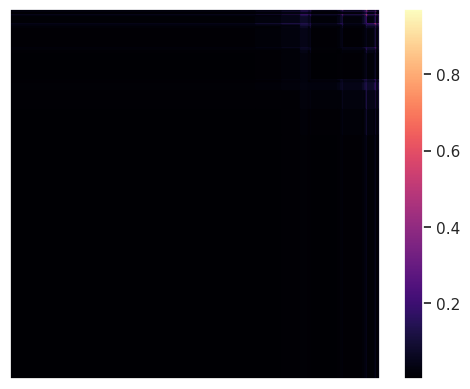

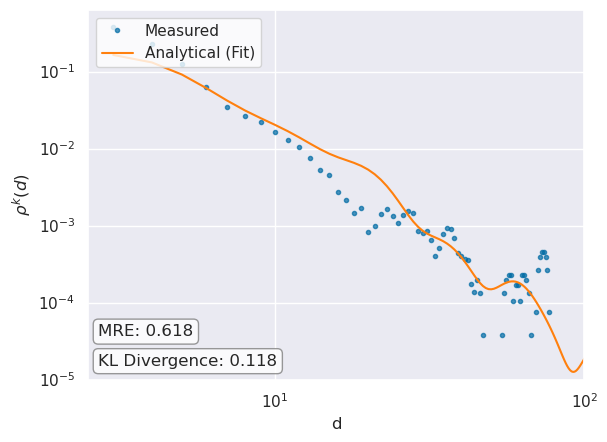

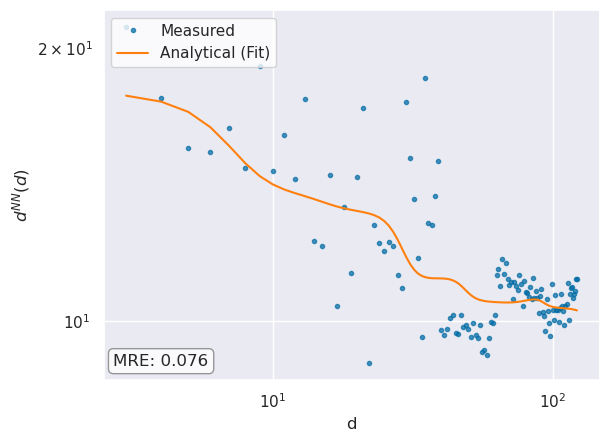

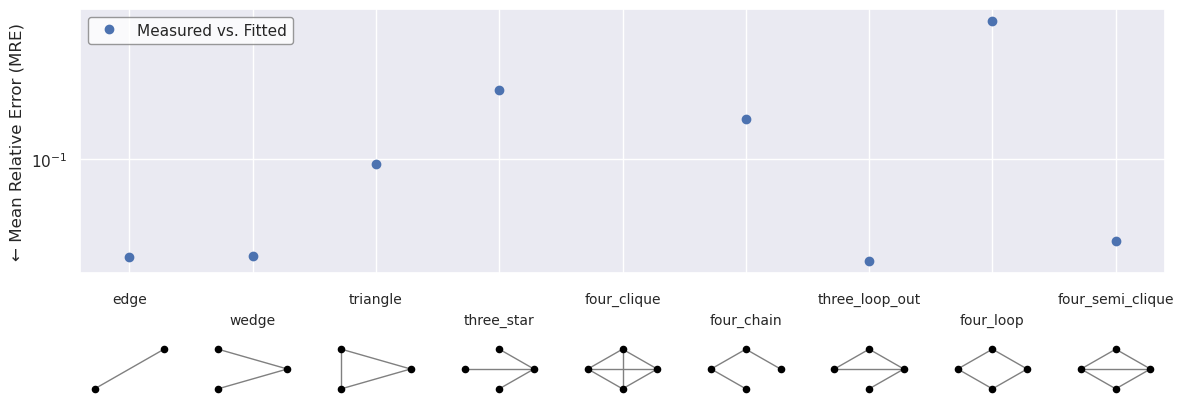

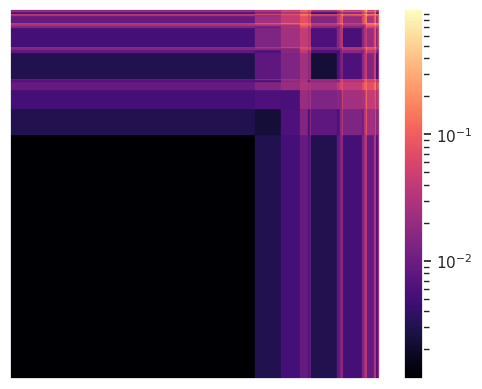

In [12]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/ba_graph_1000_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = [0,100],
    ylim = [1e-5,0],
    #filename = "figures/ba_graph_1000_log_plot.pdf"
)

# Bootstrapping Stability

In [13]:
mfnf.population_size = 100

In [67]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'mean'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [33:19<00:00, 66.65s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.505540
Energy = 7.72 (7.09, 8.33)
l = [0.73 (0.49, 0.88), 0.15 (0.05, 0.34), 0.07 (0.01, 0.17), 0.03 (0.00, 0.08), 0.02 (0.00, 0.05), 0.01 (0.00, 0.03)]
P = [
[0.04 (0.02, 0.10), 0.07 (0.01, 0.21), 0.12 (0.01, 0.26), 0.22 (0.01, 0.54), 0.34 (0.03, 0.87), 0.36 (0.00, 0.83)],

[0.07 (0.01, 0.21), 0.21 (0.01, 0.70), 0.23 (0.00, 0.68), 0.30 (0.01, 0.97), 0.40 (0.05, 0.97), 0.48 (0.04, 0.99)],

[0.12 (0.01, 0.26), 0.23 (0.00, 0.68), 0.38 (0.04, 0.89), 0.43 (0.03, 0.99), 0.50 (0.07, 0.98), 0.56 (0.08, 0.98)],

[0.22 (0.01, 0.54), 0.30 (0.01, 0.97), 0.43 (0.03, 0.99), 0.58 (0.04, 1.00), 0.52 (0.06, 0.98), 0.60 (0.18, 0.96)],

[0.34 (0.03, 0.87), 0.40 (0.05, 0.97), 0.50 (0.07, 0.98), 0.52 (0.06, 0.98), 0.57 (0.11, 0.97), 0.63 (0.14, 0.99)],

[0.36 (0.00, 0.83), 0.48 (0.04, 0.99), 0.56 (0.08, 0.98), 0.60 (0.18, 0.96), 0.63 (0.14, 0.99), 0.56 (0.03, 0.94)]
]


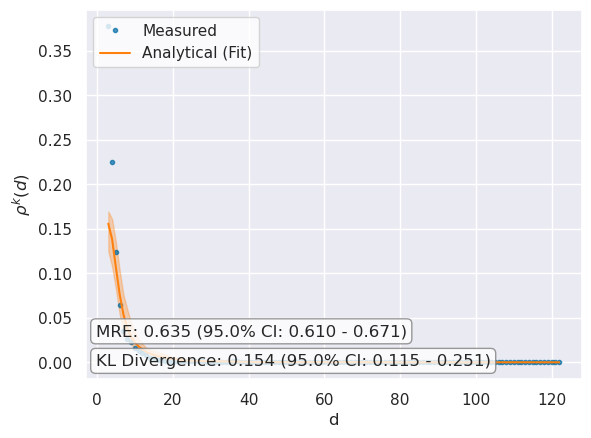

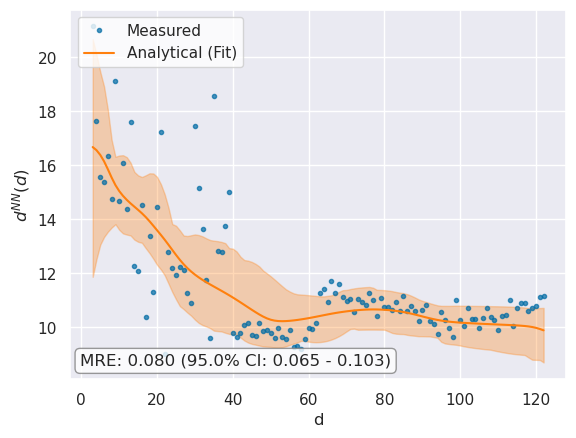

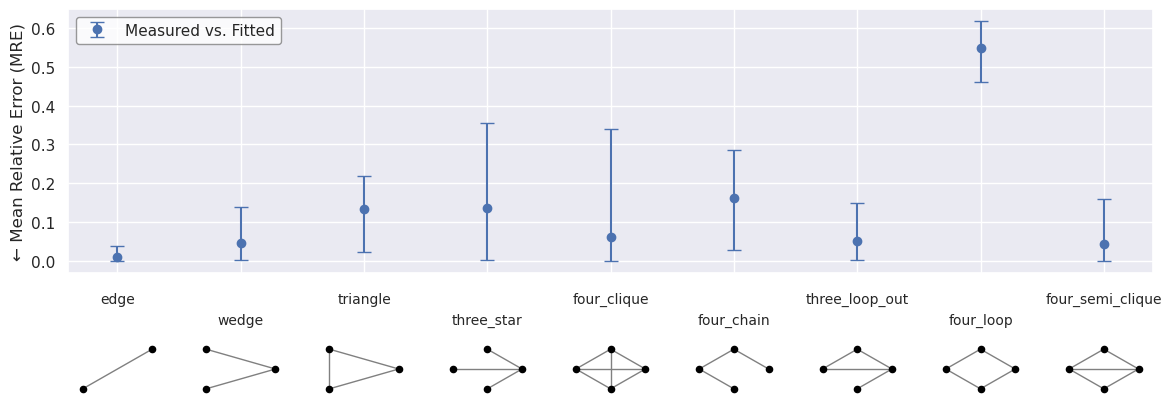

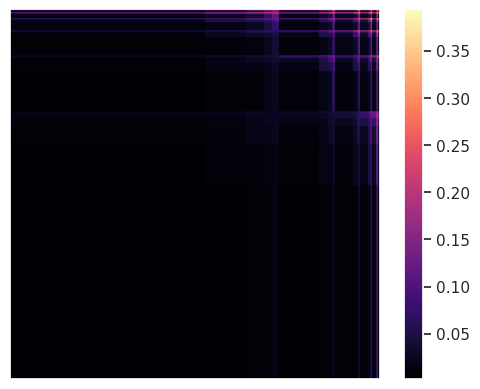

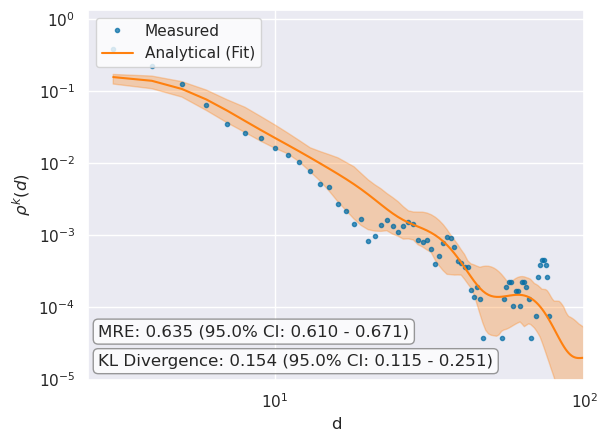

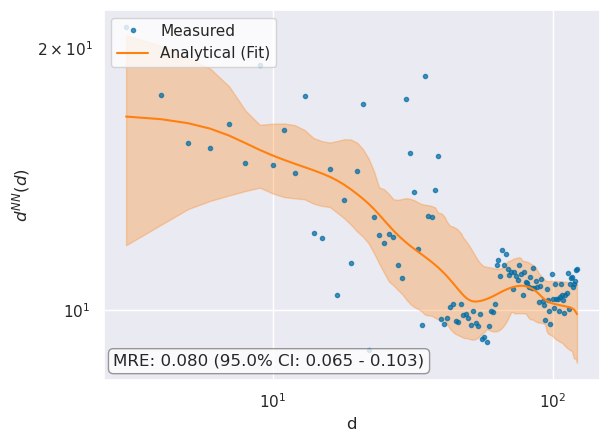

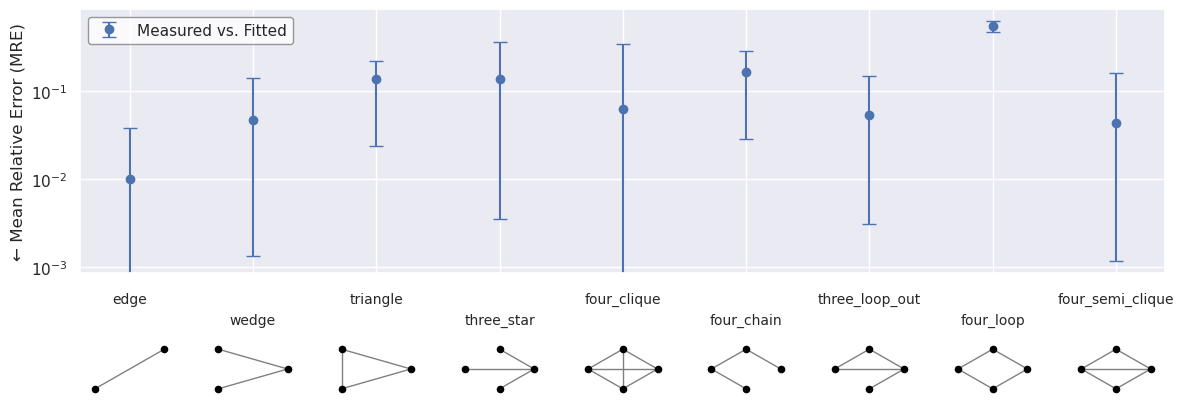

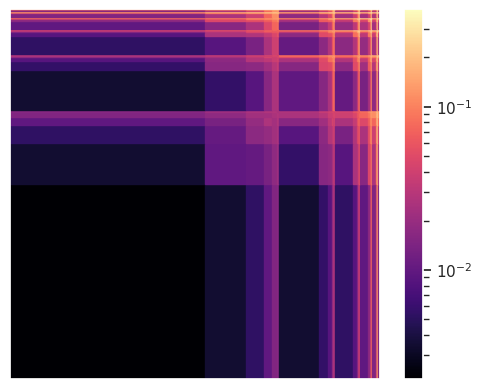

In [68]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/ba_graph_1000_plot_bootstrap.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = [0,100],
    ylim = [1e-5,0],
    filename = "figures/ba_graph_1000_log_plot_bootstrap.pdf"
)

In [75]:
mfnf.motifs[0]

{'name': 'edge',
 'matrix': array([[0, 1],
        [1, 0]]),
 'size': 2,
 'count': 2994,
 'expected_count': 2988.96,
 'MRE': 0.009849174621349951,
 'expected_count_ci_low': 2891.0,
 'expected_count_ci_high': 3109.1,
 'MRE_ci_low': 0.0,
 'MRE_ci_high': 0.037513326234597126}

In [69]:
import pickle
with open('./test_networks/ba_graph_1000_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

# Scaling the network

In [70]:
def recommend_N_for_k_range(P, l, k, avg_degree, k_limit):
    s2 = np.sum(np.outer(l, l) * P)
    recommendations = {}
    for new_k in range(k + 1, k_limit + 1):
        # Calculate the required network size N
        edge_proba_k = s2**new_k
        recommended_N = int(2 * avg_degree / edge_proba_k + 1)
        recommendations[new_k] = recommended_N
    
    return recommendations

In [85]:
recommend_N_for_k_range(mfnf.P, mfnf.l, mfnf.k, 2 * G.number_of_edges() / G.number_of_nodes(), 5)

{3: 13683, 4: 143044, 5: 1495404}

## Generating a new BA graphs

In [86]:
G_medium = generate_ba_graph(13683)

In [87]:
nx.write_graphml(G_medium, "test_networks/ba_graph_medium.graphml")

In [88]:
G_large = generate_ba_graph(143044)

In [89]:
nx.write_graphml(G_large, "test_networks/ba_graph_large.graphml")

## medium - Checking against the measure

In [90]:
mfnf_no_fit = MultifractalNetworkFitter(
    G_medium,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    },
    #pre_loaded_motifs = './test_networks/ba_graph_medium_motifs.pkl'
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:02.506236
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:05:11.835482


In [91]:
mfnf_no_fit.save_motifs('./test_networks/ba_graph_medium_motifs.pkl')

In [92]:
from copy import deepcopy

In [93]:
mfnf_no_fit.P = deepcopy(mfnf.P)
mfnf_no_fit.l = deepcopy(mfnf.l)
mfnf_no_fit.k = 3
mfnf_no_fit.resampled_best_candidates = deepcopy(mfnf.resampled_best_candidates)
mfnf_no_fit.resampled_best_energies = deepcopy(mfnf.resampled_best_energies)
mfnf_no_fit.bootstrap = True
mfnf_no_fit._calculate_bootstrap_metrics(ci = 0.95, medoid = 'mean')

Energy = 7.72 (7.09, 8.33)
l = [0.73 (0.49, 0.88), 0.15 (0.05, 0.34), 0.07 (0.01, 0.17), 0.03 (0.00, 0.08), 0.02 (0.00, 0.05), 0.01 (0.00, 0.03)]
P = [
[0.04 (0.02, 0.10), 0.07 (0.01, 0.21), 0.12 (0.01, 0.26), 0.22 (0.01, 0.54), 0.34 (0.03, 0.87), 0.36 (0.00, 0.83)],

[0.07 (0.01, 0.21), 0.21 (0.01, 0.70), 0.23 (0.00, 0.68), 0.30 (0.01, 0.97), 0.40 (0.05, 0.97), 0.48 (0.04, 0.99)],

[0.12 (0.01, 0.26), 0.23 (0.00, 0.68), 0.38 (0.04, 0.89), 0.43 (0.03, 0.99), 0.50 (0.07, 0.98), 0.56 (0.08, 0.98)],

[0.22 (0.01, 0.54), 0.30 (0.01, 0.97), 0.43 (0.03, 0.99), 0.58 (0.04, 1.00), 0.52 (0.06, 0.98), 0.60 (0.18, 0.96)],

[0.34 (0.03, 0.87), 0.40 (0.05, 0.97), 0.50 (0.07, 0.98), 0.52 (0.06, 0.98), 0.57 (0.11, 0.97), 0.63 (0.14, 0.99)],

[0.36 (0.00, 0.83), 0.48 (0.04, 0.99), 0.56 (0.08, 0.98), 0.60 (0.18, 0.96), 0.63 (0.14, 0.99), 0.56 (0.03, 0.94)]
]


In [94]:
mfnf_no_fit.motifs[0]

{'name': 'edge',
 'matrix': array([[0, 1],
        [1, 0]]),
 'size': 2,
 'count': 41043,
 'expected_count': 43342.55,
 'MRE': 0.052500403444105635,
 'expected_count_ci_low': 41230.0,
 'expected_count_ci_high': 45988.2,
 'MRE_ci_low': 0.0045355323793354356,
 'MRE_ci_high': 0.10753111709970138}

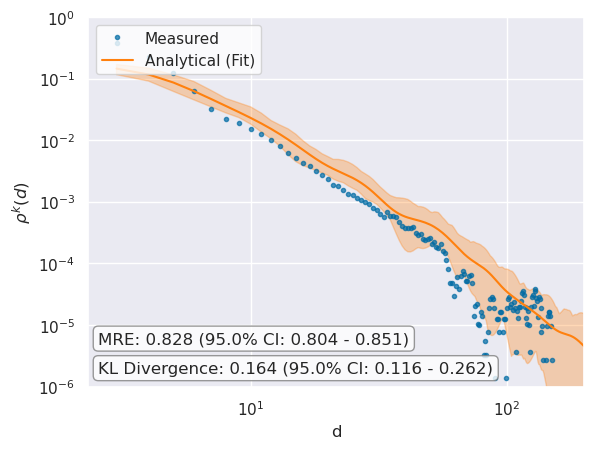

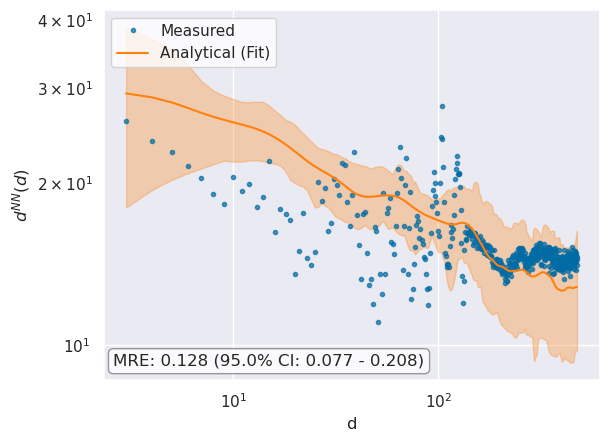

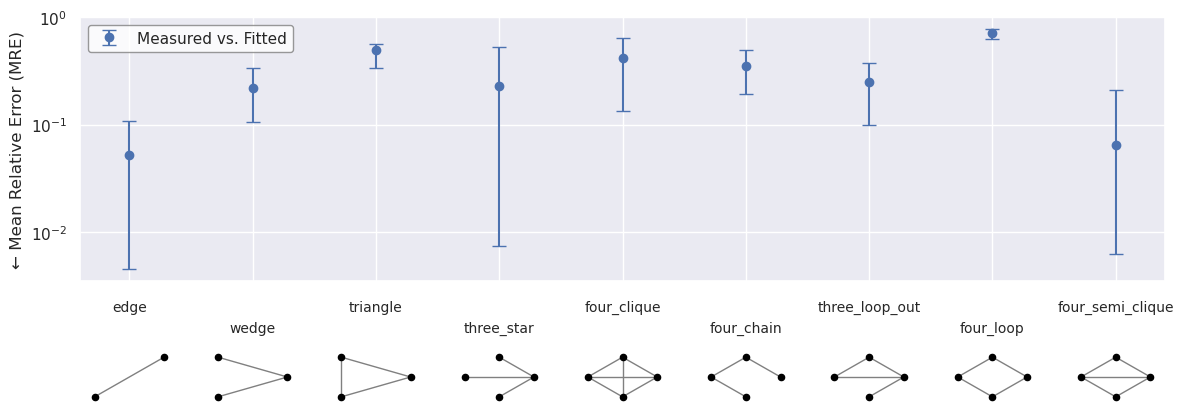

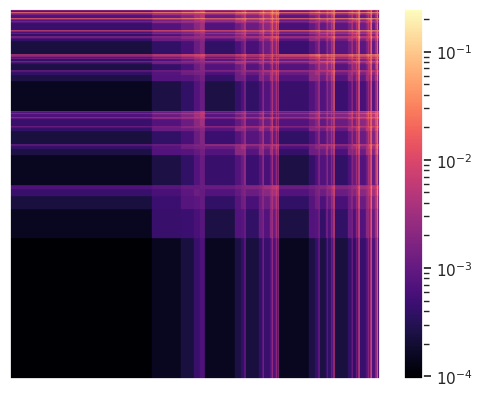

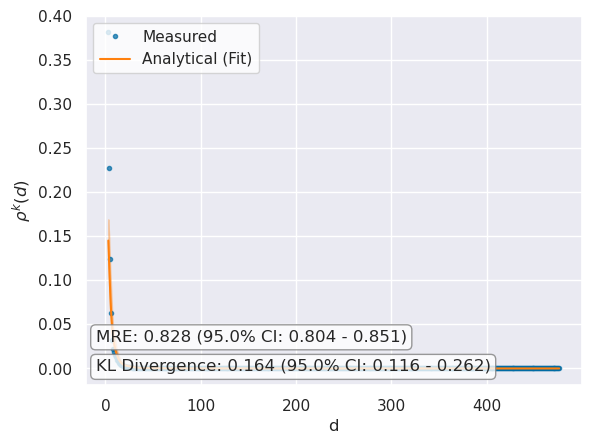

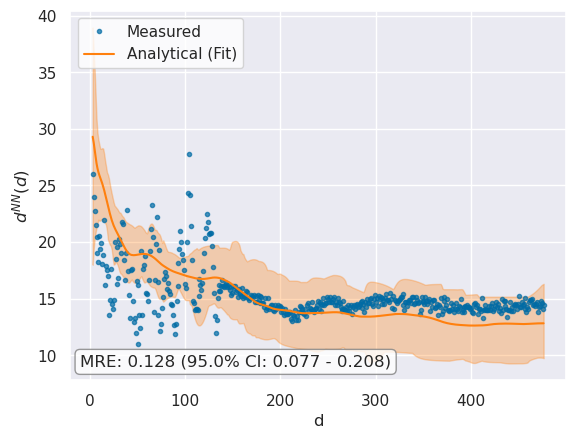

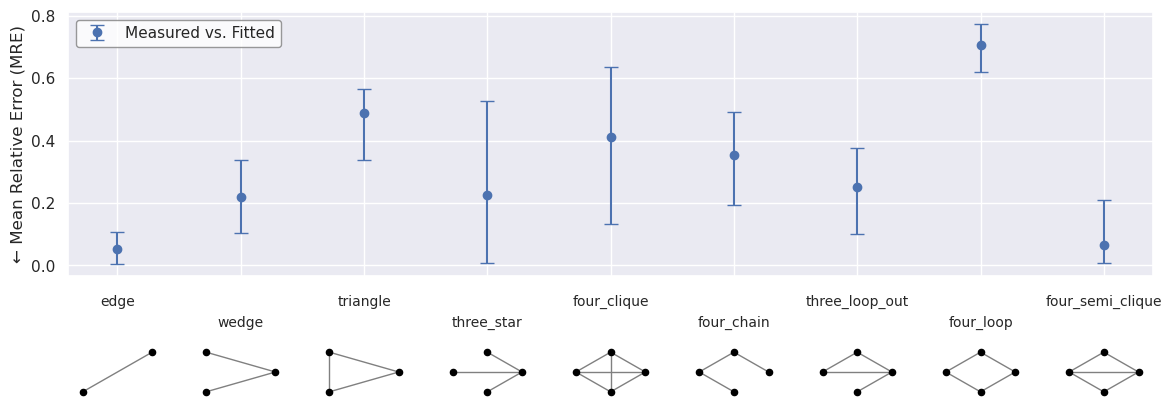

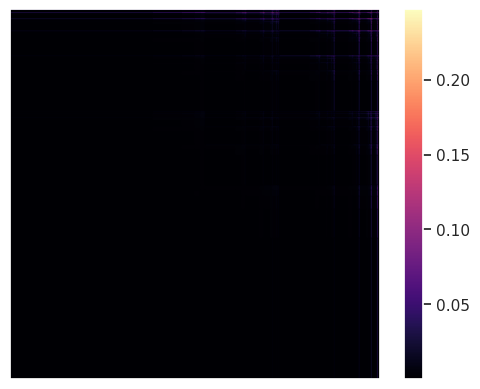

In [100]:
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = [0,200],
    ylim = [1e-6,1e0],
    filename = "figures/ba_graph_medium_log_plot.pdf"
)
mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #xlim = [0,800],
    #ylim = [1e-9,0],
    filename = "figures/ba_graph_medium_plot.pdf"
)

## large  - Checking against the measure

In [102]:
mfnf_no_fit_2 = MultifractalNetworkFitter(
    G_large,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:48.709958
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 4:24:27.232407


In [103]:
mfnf_no_fit_2.save_motifs('./test_networks/ba_graph_large_motifs.pkl')

In [104]:
mfnf_no_fit_2.P = deepcopy(mfnf.P)
mfnf_no_fit_2.l = deepcopy(mfnf.l)
mfnf_no_fit_2.k = 4
mfnf_no_fit_2.resampled_best_candidates = deepcopy(mfnf.resampled_best_candidates)
mfnf_no_fit_2.resampled_best_energies = deepcopy(mfnf.resampled_best_energies)
mfnf_no_fit_2.bootstrap = True
mfnf_no_fit_2._calculate_bootstrap_metrics(ci = 0.95, medoid = 'mean')

Energy = 7.72 (7.09, 8.33)
l = [0.73 (0.49, 0.88), 0.15 (0.05, 0.34), 0.07 (0.01, 0.17), 0.03 (0.00, 0.08), 0.02 (0.00, 0.05), 0.01 (0.00, 0.03)]
P = [
[0.04 (0.02, 0.10), 0.07 (0.01, 0.21), 0.12 (0.01, 0.26), 0.22 (0.01, 0.54), 0.34 (0.03, 0.87), 0.36 (0.00, 0.83)],

[0.07 (0.01, 0.21), 0.21 (0.01, 0.70), 0.23 (0.00, 0.68), 0.30 (0.01, 0.97), 0.40 (0.05, 0.97), 0.48 (0.04, 0.99)],

[0.12 (0.01, 0.26), 0.23 (0.00, 0.68), 0.38 (0.04, 0.89), 0.43 (0.03, 0.99), 0.50 (0.07, 0.98), 0.56 (0.08, 0.98)],

[0.22 (0.01, 0.54), 0.30 (0.01, 0.97), 0.43 (0.03, 0.99), 0.58 (0.04, 1.00), 0.52 (0.06, 0.98), 0.60 (0.18, 0.96)],

[0.34 (0.03, 0.87), 0.40 (0.05, 0.97), 0.50 (0.07, 0.98), 0.52 (0.06, 0.98), 0.57 (0.11, 0.97), 0.63 (0.14, 0.99)],

[0.36 (0.00, 0.83), 0.48 (0.04, 0.99), 0.56 (0.08, 0.98), 0.60 (0.18, 0.96), 0.63 (0.14, 0.99), 0.56 (0.03, 0.94)]
]


In [105]:
mfnf_no_fit_2.motifs[0]

{'name': 'edge',
 'matrix': array([[0, 1],
        [1, 0]]),
 'size': 2,
 'count': 429126,
 'expected_count': 366540.09,
 'MRE': 0.14584506648396975,
 'expected_count_ci_low': 342868.0,
 'expected_count_ci_high': 396618.575,
 'MRE_ci_low': 0.07575263442438818,
 'MRE_ci_high': 0.20100856158797184}

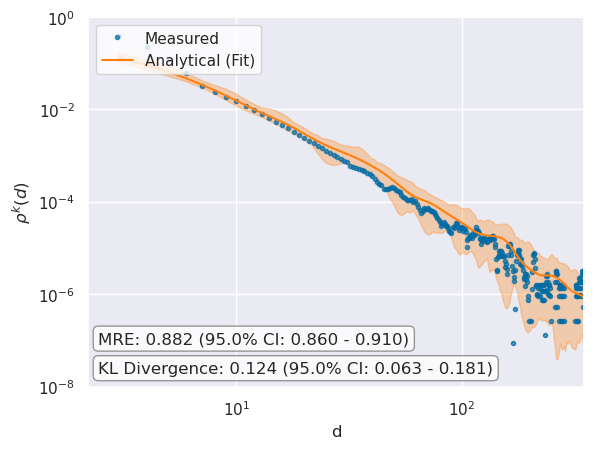

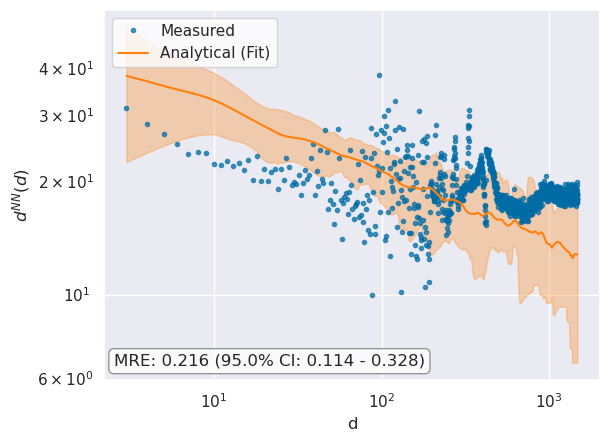

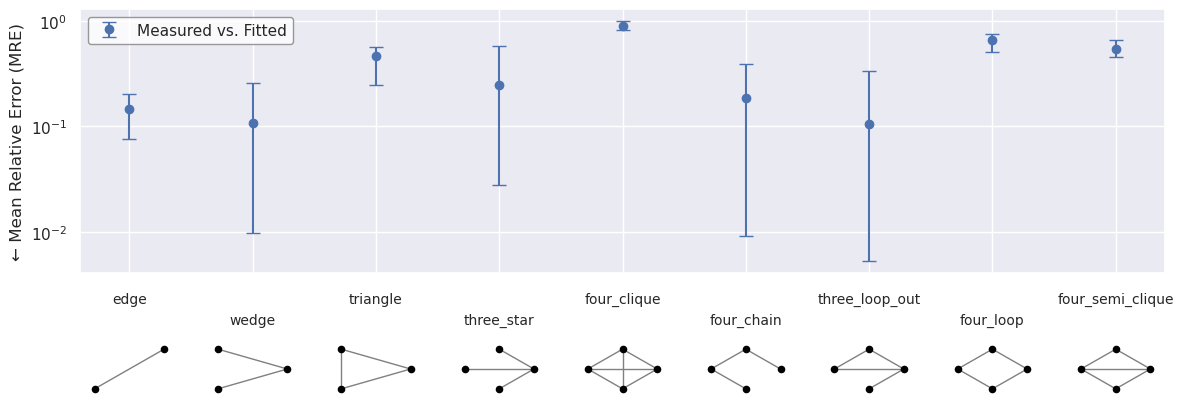

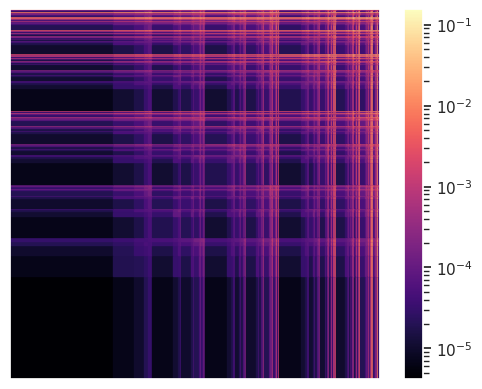

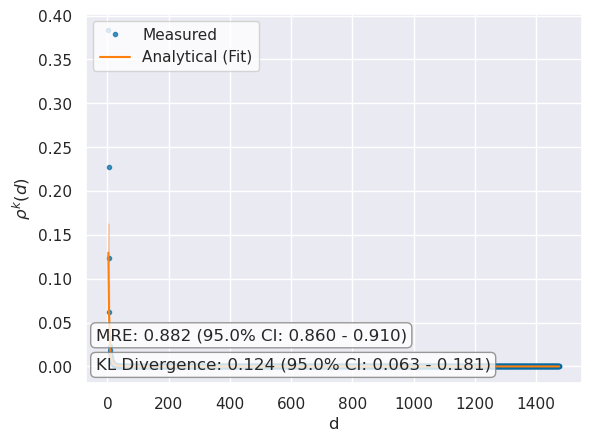

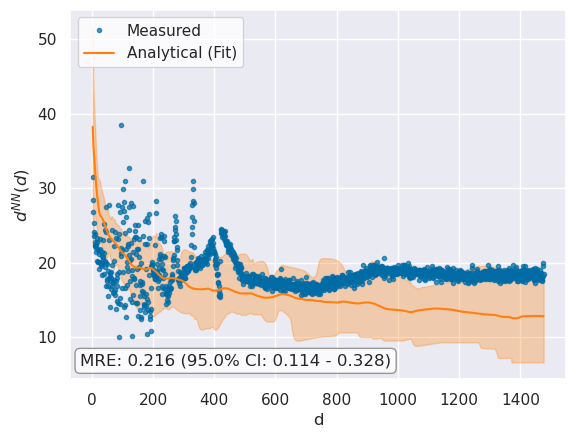

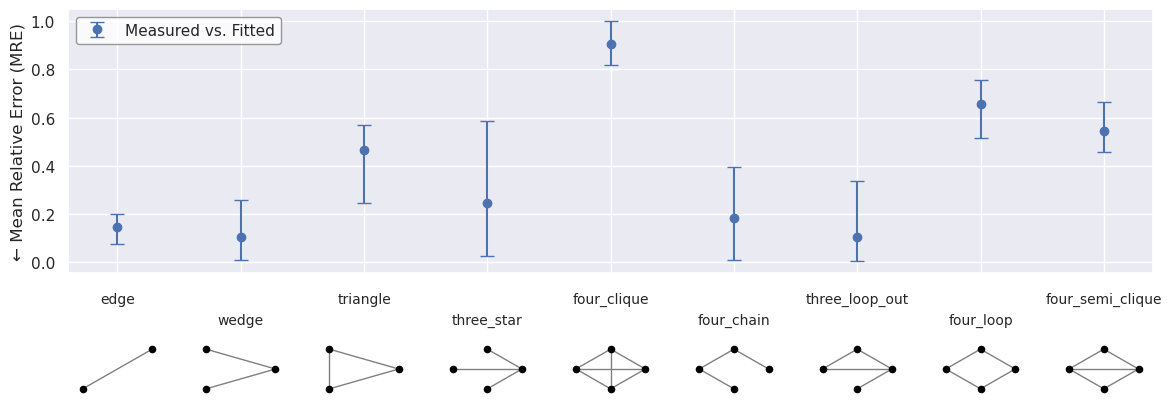

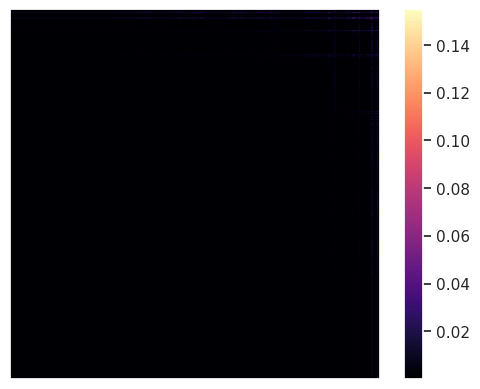

In [106]:
mfnf_no_fit_2.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    xlim = [0,350],
    ylim = [1e-8,1e0],
    filename = "figures/ba_graph_large_log_plot.pdf"
)
mfnf_no_fit_2.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #xlim = [0,800],
    #ylim = [1e-9,0],
    filename = "figures/ba_graph_large_plot.pdf"
)